# 02 - Calidad CNMC/MIBGAS -> processed

Este notebook clasifica los raw, filtra la ventana comun, normaliza los precios y deduplica por fecha y producto. No inventa valores para dias sin cobertura ni confunde fecha de negociacion con fecha de publicacion.

In [7]:
import json
import sys
import importlib
from pathlib import Path

import pandas as pd

def find_project_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / 'requirements.txt').is_file() and (candidate / 'notebooks').is_dir():
            return candidate
    raise FileNotFoundError('No se encontro la raiz del proyecto.')

PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT))
import src.calidad.cnmc as cnmc_quality
importlib.reload(cnmc_quality)
from src.cnmc_config import load_cnmc_config
from src.calidad.cnmc import classify_raw_file, deduplicate_records, normalize_records
from src.ingesta.cnmc import CnmcResourceConfig

CONFIG = load_cnmc_config(PROJECT_ROOT / 'config' / 'cnmc.yml')
CNMC = CONFIG['cnmc']
MODEL = CNMC['model']
RAW_DIR = PROJECT_ROOT / 'data' / 'raw' / 'cnmc'
OUT_DIR = PROJECT_ROOT / 'data' / 'processed' / 'cnmc'
START = MODEL['history_start']
END = MODEL['history_end']

In [5]:
raw_files = sorted(RAW_DIR.glob('*.json'))
if not raw_files:
    raise FileNotFoundError(f'No hay raw CNMC en {RAW_DIR}')

classified = [classify_raw_file(path) for path in raw_files]
pd.DataFrame([{k: v for k, v in item.items() if k != 'payload'} for item in classified])

,source_file,status,record_count,captured_at_utc,error
0,c:\Users\zhen.xiang\OneDrive - Accenture\Docum...,valid,3820,2026-11-16T12:39:23.910939+00:00,None
1,c:\Users\zhen.xiang\OneDrive - Accenture\Docum...,valid,14673,2026-11-16T12:39:55.080481+00:00,None


In [8]:
frames = []
reports = []
for item in classified:
    if item['status'] != 'valid':
        continue
    resource_name = item['payload']['resource']
    resource = CnmcResourceConfig(name=resource_name, **CNMC['resources'][resource_name])
    values, report = normalize_records(item['payload'], resource, START, END)
    frames.append(values)
    reports.append(report | {'resource': resource_name})

values = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
values, duplicates_removed = deduplicate_records(values)
OUT_DIR.mkdir(parents=True, exist_ok=True)
values.to_json(OUT_DIR / 'cnmc_diario.json', orient='records', date_format='iso', force_ascii=False, indent=2)
quality_report = {
    'configured_window': {'start': str(START), 'end': str(END)},
    'raw_files': len(raw_files),
    'reports': reports,
    'output_records': len(values),
    'duplicates_removed': duplicates_removed,
}
(OUT_DIR / 'calidad_cnmc.json').write_text(json.dumps(quality_report, ensure_ascii=False, indent=2), encoding='utf-8')
quality_report

{'configured_window': {'start': '2024-10-01', 'end': '2026-09-30'},
 'raw_files': 2,
 'reports': [{'input_records': 3820,
   'output_records': 608,
   'invalid_dates': 0,
   'invalid_prices': 0,
   'outside_window': 3212,
   'filtered_by_product': 0,
   'resource': 'indice_mibgas'},
  {'input_records': 14673,
   'output_records': 608,
   'invalid_dates': 0,
   'invalid_prices': 0,
   'outside_window': 10511,
   'filtered_by_product': 3554,
   'resource': 'producto_diario_d1'}],
 'output_records': 1216,
 'duplicates_removed': 0}

## 4. Diagnóstico visual

Los gráficos permiten comprobar la cobertura temporal, los registros descartados por ventana o producto y la evolución de los precios procesados.

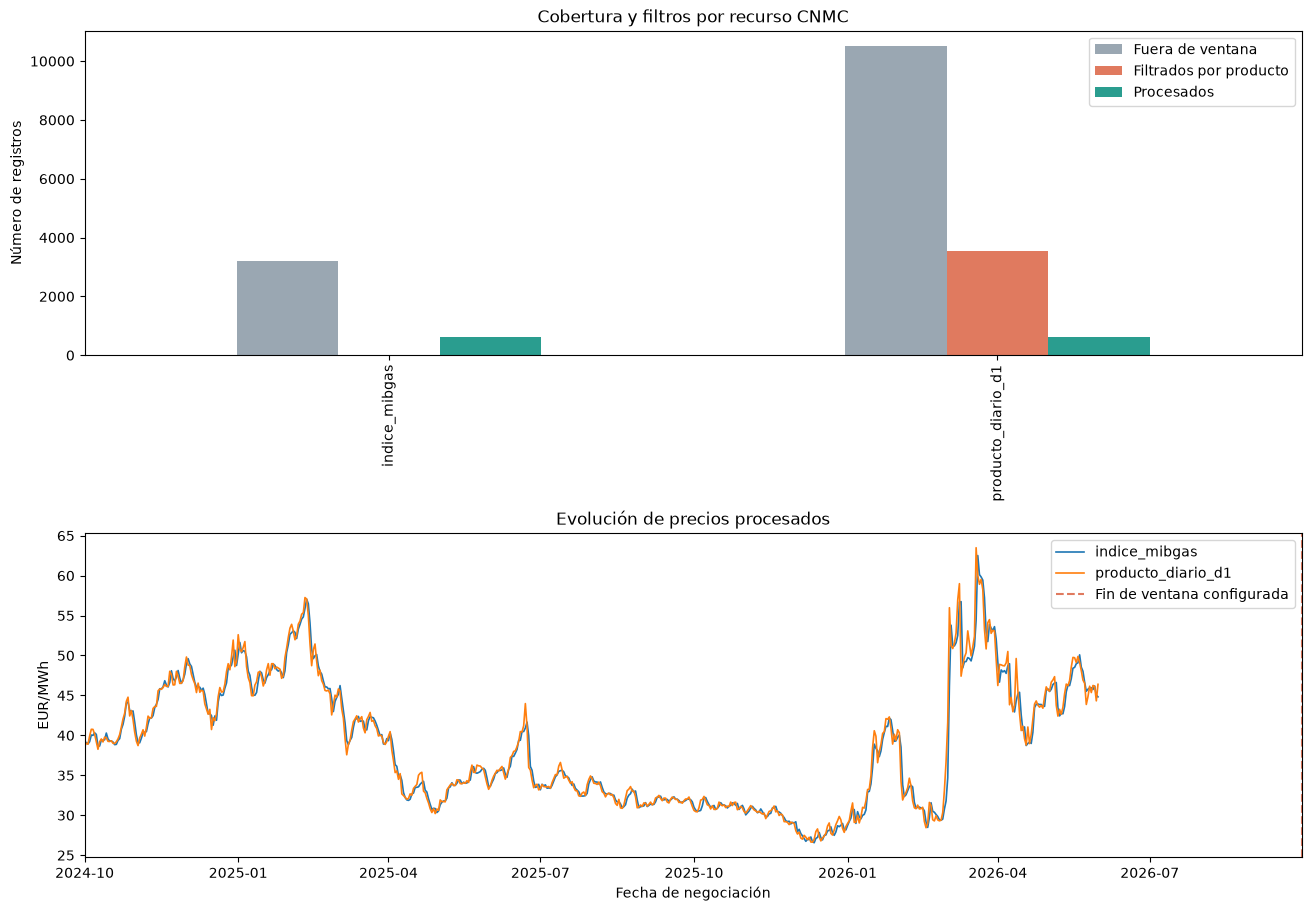

,resource,within_window,filtered_by_product,output_records
0,indice_mibgas,608,0,608
1,producto_diario_d1,4162,3554,608


In [9]:
import matplotlib.pyplot as plt

report_frame = pd.DataFrame(reports)
report_frame["within_window"] = report_frame["input_records"] - report_frame["outside_window"]

fig, axes = plt.subplots(2, 1, figsize=(13, 9), constrained_layout=True)
report_frame.set_index("resource")[[
    "outside_window", "filtered_by_product", "output_records"
]].plot.bar(ax=axes[0], color=["#9aa7b2", "#e07a5f", "#2a9d8f"])
axes[0].set_title("Cobertura y filtros por recurso CNMC")
axes[0].set_ylabel("Número de registros")
axes[0].set_xlabel("")
axes[0].legend(["Fuera de ventana", "Filtrados por producto", "Procesados"])

values_plot = values.copy()
values_plot["fecha_negociacion"] = pd.to_datetime(values_plot["fecha_negociacion"])
for resource_name, group in values_plot.groupby("source_resource"):
    group = group.sort_values("fecha_negociacion")
    axes[1].plot(
        group["fecha_negociacion"],
        group["precio_eur_mwh"],
        label=resource_name,
        linewidth=1.2,
    )
axes[1].axvline(pd.Timestamp(END), color="#e07a5f", linestyle="--", label="Fin de ventana configurada")
axes[1].set_title("Evolución de precios procesados")
axes[1].set_ylabel("EUR/MWh")
axes[1].set_xlabel("Fecha de negociación")
axes[1].set_xlim(pd.Timestamp(START), pd.Timestamp(END))
axes[1].legend()
plt.show()

report_frame[[
    "resource", "within_window", "filtered_by_product", "output_records"
]]